# Proyecto Big Data — OSIPTEL | Pipeline visual paso a paso

**JupyterLab + PySpark** · Fuentes oficiales · `RAW → STAGING → SILVER → GOLD → EDA → modelo base`

Este notebook reemplaza la ejecución monolítica de `pipeline.run_pipeline()` por **etapas verificables**. Después de cada etapa encontrarás tablas, conteos, gráficos o mensajes de diagnóstico que puedes usar como evidencia **cuando se generen con tus datos reales**.

**Cómo usarlo:**
1. Guarda este `.ipynb` **en la misma carpeta** que `osiptel_pipeline.py`, dentro de `~/BigData_UPAO/OSIPTEL_Pipeline_PySpark/`.
2. Conserva los datos oficiales en `data/raw/01_agregados`, `02_historicos` (pueden ser cuatro ZIP de 2012–2015) y `03_cobertura`.
3. Ejecuta las celdas **en orden**, con `Shift + Enter`; espera a que `In [*]` termine antes de pasar a la siguiente.
4. El código escribe resultados en `data/lake/` **local**, no en HDFS, salvo que configures `OSIPTEL_LAKE_URI` previamente.

> Precauciones: los reportes agregados y los eventos históricos no son cantidades sumables; la cobertura **no localiza delitos**. No se fabrican observaciones ni métricas.

## 0. Dependencias y configuración

Ejecuta primero la siguiente celda. **No instala paquetes automáticamente** para no modificar tu entorno de Spark. Si falta alguno, usa la celda de instalación (comentada) y reinicia el kernel si es necesario.

In [1]:
import importlib
import osiptel_pipeline as pipeline
importlib.reload(pipeline)

<module 'osiptel_pipeline' from '/home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark/osiptel_pipeline.py'>

In [2]:
from pathlib import Path
import sys, importlib.util, importlib, json, time, os

NECESARIOS = ["pyspark", "openpyxl", "pandas", "numpy", "matplotlib"]
print("DEPENDENCIAS DEL NOTEBOOK")
for nombre in NECESARIOS:
    encontrado = importlib.util.find_spec(nombre) is not None
    print(f"  {nombre:12s}: {'OK' if encontrado else 'FALTA'}")

# Si faltan paquetes de gráficos/Excel, ejecutar en OTRA celda:
# %pip install openpyxl pandas numpy matplotlib
# Si falta pyspark, primero verifica la configuración del kernel Spark del laboratorio.

DEPENDENCIAS DEL NOTEBOOK
  pyspark     : OK
  openpyxl    : OK
  pandas      : OK
  numpy       : OK
  matplotlib  : OK


In [3]:
%pip install matplotlib
%pip install pandas openpyxl

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [4]:
# Ejecutar después de instalar las dependencias si fuera necesario.
# Esto NO ejecuta Spark ni modifica los datos.
PROJECT = Path.cwd()
if not (PROJECT / 'osiptel_pipeline.py').exists():
    if (PROJECT.parent / 'osiptel_pipeline.py').exists():
        PROJECT = PROJECT.parent
if not (PROJECT / 'osiptel_pipeline.py').exists():
    raise FileNotFoundError(
        f"No encuentro osiptel_pipeline.py desde {Path.cwd()}. "
        "Coloca este notebook junto al archivo .py y abre esa carpeta en JupyterLab."
    )
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
import osiptel_pipeline as pipeline
importlib.reload(pipeline)

print('Proyecto:', PROJECT)
print('Origen RAW:', pipeline.RAW)
print('Destino local/URI:', pipeline.OUTPUT)
print('Evidencias:', pipeline.EVIDENCE)

Proyecto: /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark
Origen RAW: /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark/data/raw
Destino local/URI: /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark/data/lake
Evidencias: /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark/docs/evidence


## 1. Diagnóstico de los archivos oficiales

Comprueba las entradas **antes de ejecutar el ETL**. Los nombres de los archivos son libres; se reconocen por extensión. No hacen falta ZIP de años que no hayas podido descargar.

In [5]:
# Importar el módulo del pipeline OSIPTEL
import osiptel_pipeline as pipeline

print("Módulo OSIPTEL importado correctamente")
print("Directorio del proyecto:", pipeline.ROOT)

Módulo OSIPTEL importado correctamente
Directorio del proyecto: /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark


In [6]:
from IPython.display import display
import pandas as pd

filas_origen = []
for nombre, carpeta in pipeline.SOURCE_DIRS.items():
    archivos = sorted(p for p in carpeta.rglob('*') if p.is_file()) if carpeta.exists() else []
    archivos_validos = [p for p in archivos if p.suffix.lower() in ('.xlsx', '.csv', '.zip', '.txt')]
    print(f'[{nombre.upper()}] {len(archivos_validos)} archivo(s) de entrada')
    for p in archivos_validos:
        tam_mb = p.stat().st_size / (1024 ** 2)
        filas_origen.append({'fuente':nombre, 'archivo':p.name, 'formato':p.suffix.lower(), 'MB':round(tam_mb,2)})
        print(f'  - {p.name} | {tam_mb:,.2f} MB')
    if not archivos_validos:
        print('  ⚠ FALTAN ARCHIVOS EN ESTA CARPETA')

if filas_origen:
    display(pd.DataFrame(filas_origen))
else:
    print('No hay datos. Debes copiarlos a las carpetas data/raw antes de continuar.')

[AGREGADOS] 1 archivo(s) de entrada
  - 9.1. EQUIPOS SUSTRAIDOS PERDIDOS O RECUPERADOS.xlsx | 0.07 MB
[HISTORICOS] 4 archivo(s) de entrada
  - 2012.csv.zip | 23.85 MB
  - 2013.csv.zip | 14.65 MB
  - 2014.csv.zip | 19.52 MB
  - 2015.csv.zip | 24.97 MB
[COBERTURA] 1 archivo(s) de entrada
  - Cobertura móvil por empresa operadora.csv | 7.24 MB


,fuente,archivo,formato,MB
0,agregados,9.1. EQUIPOS SUSTRAIDOS PERDIDOS O RECUPERADOS...,.xlsx,0.07
1,historicos,2012.csv.zip,.zip,23.85
2,historicos,2013.csv.zip,.zip,14.65
3,historicos,2014.csv.zip,.zip,19.52
4,historicos,2015.csv.zip,.zip,24.97
5,cobertura,Cobertura móvil por empresa operadora.csv,.csv,7.24


## 2. Ingesta RAW → STAGING y manifiesto de procedencia

`stage_raw_data()` lee XLSX, ZIP y CSV originales, genera CSV normalizados para Spark y un `manifest.json` con conteos y SHA-256. El IMEI, si existe, se sustituye por un HMAC.

- Si **ya se generaron `manifest.json` y los CSV de las tres fuentes**, esta celda los reutiliza para evitar repetir una ingesta costosa.
- Si cambiaste archivos de `data/raw`, la ingesta se repetirá automáticamente por fecha de modificación; también puedes cambiar `FORZAR_INGESTA = True`.
- No consideres esta etapa como pipeline completo: todavía faltan SILVER y GOLD.

In [7]:
FORZAR_INGESTA = False
manifest_path = pipeline.EVIDENCE / 'manifest.json'

archivos_raw = [p for carpeta in pipeline.SOURCE_DIRS.values()
                for p in (carpeta.rglob('*') if carpeta.exists() else [])
                if p.is_file() and p.suffix.lower() in ('.xlsx', '.zip', '.csv', '.txt')]
listo = (
    manifest_path.exists()
    and all((pipeline.STAGING / fuente).exists()
            and any((pipeline.STAGING / fuente).glob('*.csv'))
            for fuente in pipeline.SOURCE_DIRS)
)
raw_mas_nuevo = max([p.stat().st_mtime for p in archivos_raw], default=0)
datos_cambiaron = (not manifest_path.exists()) or raw_mas_nuevo > manifest_path.stat().st_mtime if manifest_path.exists() else True

if FORZAR_INGESTA or not listo or datos_cambiaron:
    print('[INICIO] Preparando RAW → STAGING; puede tardar varios minutos...', flush=True)
    t_ingesta = time.perf_counter()
    manifest = pipeline.stage_raw_data()
    print(f'[FIN] Ingesta completada en {time.perf_counter()-t_ingesta:,.1f} s', flush=True)
else:
    print('[REUTILIZADO] Manifest y CSV de staging existentes. No se releyeron archivos originales.')
    print('Si dudas de su vigencia, configura FORZAR_INGESTA=True y repite esta celda.')
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))

print('\nRUTA DEL MANIFIESTO:', manifest_path)
for fuente, info in manifest.items():
    print(f'  {fuente}: {info.get("rows", 0):,} filas en staging; '
          f'{len(info.get("files", []))} archivos/hojas; '
          f'{len(info.get("skipped", []))} recursos omitidos')

[REUTILIZADO] Manifest y CSV de staging existentes. No se releyeron archivos originales.
Si dudas de su vigencia, configura FORZAR_INGESTA=True y repite esta celda.

RUTA DEL MANIFIESTO: /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark/docs/evidence/manifest.json
  agregados: 1,698 filas en staging; 1 archivos/hojas; 0 recursos omitidos
  historicos: 15,821,240 filas en staging; 4 archivos/hojas; 0 recursos omitidos
  cobertura: 51,366 filas en staging; 1 archivos/hojas; 0 recursos omitidos


,Fuente,Registros en staging,Archivos/hojas leídos,Recursos omitidos
0,agregados,1698,1,0
1,historicos,15821240,4,0
2,cobertura,51366,1,0


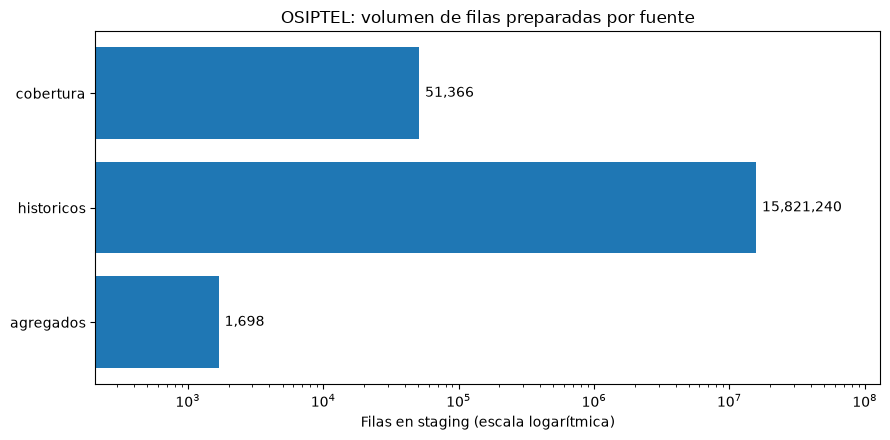

INTERPRETACIÓN: las tres fuentes tienen unidades de registro distintas; NO sumarlas como robos.


In [8]:
# EVIDENCIA 1: tabla + gráfico del MANIFEST REAL
import matplotlib.pyplot as plt

resumen_ingesta = pd.DataFrame([
    {'Fuente': fuente, 'Registros en staging': int(info.get('rows',0)),
     'Archivos/hojas leídos': len(info.get('files',[])),
     'Recursos omitidos': len(info.get('skipped',[]))}
    for fuente, info in manifest.items()
])
display(resumen_ingesta)

if not resumen_ingesta.empty:
    fig, ax = plt.subplots(figsize=(9,4.5))
    rects = ax.barh(resumen_ingesta['Fuente'], resumen_ingesta['Registros en staging'])
    vals = resumen_ingesta['Registros en staging'].tolist()
    if min(vals) > 0 and max(vals)/min(vals) > 100:
        ax.set_xscale('log')
        ax.set_xlabel('Filas en staging (escala logarítmica)')
    else:
        ax.set_xlabel('Filas en staging')
    if hasattr(ax, 'bar_label'):
        ax.bar_label(rects, labels=[f'{v:,}' for v in vals], padding=4)
    ax.set_title('OSIPTEL: volumen de filas preparadas por fuente')
    ax.margins(x=.23)
    plt.tight_layout()
    plt.show()
    print('INTERPRETACIÓN: las tres fuentes tienen unidades de registro distintas; NO sumarlas como robos.')

## 3. Iniciar Spark y verificar el entorno

Esta celda debe imprimir versión, *master* y una tabla de prueba. Si se queda en `In [*]` sin terminar, **Spark todavía está trabajando o no está iniciando**. Diagnostica esta etapa antes de continuar.

In [9]:
import os
import sys

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["SPARK_HOME"] = "/opt/spark-3.5.1-bin-hadoop3"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

try:
    spark.stop()
except:
    pass

# Se añade la configuración de tiempo en modo LEGACY para soportar fechas con formato 'a.m./p.m.'
spark = SparkSession.builder \
    .appName("Proyecto") \
    .config("spark.sql.legacy.timeParserPolicy", "LEGACY") \
    .getOrCreate()

sc = spark.sparkContext

print(
    "SparkSession y SparkContext iniciados con éxito. Versión de Spark:",
    spark.version,
)

26/10/12 10:07:03 WARN Utils: Your hostname, Bigdata resolves to a loopback address: 127.0.1.1; using 10.0.2.15 instead (on interface enp0s3)
26/10/12 10:07:03 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/12 10:07:06 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


SparkSession y SparkContext iniciados con éxito. Versión de Spark: 3.5.1


## 4. Vista preliminar de STAGING (sin limpiar)

Muestra solamente cinco filas por fuente. Esto demuestra que Spark puede **leer** las salidas de la ingesta. No es aún el análisis exploratorio sobre datos limpios.

In [10]:
for fuente in ('agregados','historicos','cobertura'):
    print(f'\n[STAGING] {fuente.upper()} — primeras 5 filas (columnas seleccionadas)', flush=True)
    df = pipeline.read_stage(spark, fuente)
    columnas_seguras = {
        'agregados':['operadora','anio','mes','estado','cantidad'],
        'historicos':['fechahora','reporte','pais','operadora','tecnologia'],
        'cobertura':['periodo','operadora','departamento','ubigeo_ccpp','4g'],
    }[fuente]
    df.select(*[c for c in columnas_seguras if c in df.columns]).show(5,truncate=35)
print('[OK] Las tres fuentes se han podido consultar mediante Spark')


[STAGING] AGREGADOS — primeras 5 filas (columnas seleccionadas)


26/10/12 10:07:23 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors
                                                                                

+-------------------------+----+-------------------+-----------+--------+
|                operadora|anio|                mes|     estado|cantidad|
+-------------------------+----+-------------------+-----------+--------+
|América Movil Perú S.A.C.|2017|2017-01-01 00:00:00| Sustraídos|   63710|
|América Movil Perú S.A.C.|2017|2017-01-01 00:00:00|Recuperados|    5902|
|América Movil Perú S.A.C.|2017|2017-01-01 00:00:00|   Perdidos|   32283|
|          Entel Perú S.A.|2017|2017-01-01 00:00:00| Sustraídos|   52146|
|          Entel Perú S.A.|2017|2017-01-01 00:00:00|Recuperados|    4452|
+-------------------------+----+-------------------+-----------+--------+
only showing top 5 rows


[STAGING] HISTORICOS — primeras 5 filas (columnas seleccionadas)
+------------------------+---------+----+---------+----------+
|               fechahora|  reporte|pais|operadora|tecnologia|
+------------------------+---------+----+---------+----------+
|03/01/2012 05:01:54 a.m.|Bloqueado|Perú|    ENTEL|   

## 5. SILVER: limpieza, validación y escritura por fuente

La ejecución de `pipeline.run_pipeline()` se sustituye por **tres celdas independientes**. Cada una transforma datos, reporta aceptados/rechazados, escribe Parquet en `data/lake/silver/` y guarda rechazos en `data/lake/rejects/`.

Puede tardar especialmente la fuente histórica. **No ejecutes la siguiente celda mientras la actual muestre `In [*]`.**

In [11]:
# Función auxiliar usada por las TRES celdas SILVER posteriores.
# Los conteos de calidad ocurren antes de la deduplicación interna; el conteo
# final escrito en Parquet puede ser inferior si había duplicados.
from pyspark.sql import functions as F

calidad_parcial = pipeline.EVIDENCE / 'calidad_por_etapas.json'
pipeline.EVIDENCE.mkdir(parents=True, exist_ok=True)
if calidad_parcial.exists():
    calidad_fuentes = json.loads(calidad_parcial.read_text(encoding='utf-8'))
else:
    calidad_fuentes = {}

def procesar_fuente(nombre, funcion, mostrar):
    print(f'\n[INICIO SILVER] {nombre.upper()} — procesando y validando...', flush=True)
    t0 = time.perf_counter()
    validos, rechazados, resumen = funcion(spark)
    silver_path = f'{pipeline.OUTPUT}/silver/{nombre}'
    rejects_path = f'{pipeline.OUTPUT}/rejects/{nombre}'
    print(f'[ESCRITURA] {silver_path}',flush=True)
    validos.write.mode('overwrite').parquet(silver_path)
    print(f'[ESCRITURA] {rejects_path}',flush=True)
    rechazados.write.mode('overwrite').parquet(rejects_path)
    recargado = spark.read.parquet(silver_path)
    n_guardado = recargado.count()
    resumen['filas_guardadas_silver'] = n_guardado
    resumen['tiempo_silver_s'] = round(time.perf_counter()-t0, 2)
    calidad_fuentes[nombre] = resumen
    calidad_parcial.write_text(json.dumps(calidad_fuentes,indent=2,ensure_ascii=False),encoding='utf-8')
    print(f'[FIN SILVER] {nombre.upper()}: {resumen["tiempo_silver_s"]} segundos')
    print('  Totales:',resumen['total'], '| Aceptados antes de deduplicar:',resumen['aceptados'],
          '| Rechazados:',resumen['rechazados'])
    print('  Filas guardadas después de deduplicar:',n_guardado)
    print('  Porcentaje que cumple validaciones:', resumen['completitud_valida_pct'],'%')
    recargado.select(*mostrar).show(10,truncate=35)
    print('  Reporte:',calidad_parcial)
    return recargado

print('[OK] Función procesar_fuente lista. Continúa con agregados, históricos y cobertura.')

[OK] Función procesar_fuente lista. Continúa con agregados, históricos y cobertura.


In [12]:
from pyspark.sql import functions as F

print("=== DIAGNÓSTICO SILVER 5.1 ===")

rechazados = spark.read.parquet(
    f"{pipeline.OUTPUT}/rejects/agregados"
)

print("\nMOTIVOS DE RECHAZO:")
(
    rechazados
    .groupBy("motivo_rechazo")
    .count()
    .orderBy(F.desc("count"))
    .show(30, truncate=False)
)

print("\nMUESTRA DE REGISTROS RECHAZADOS:")
rechazados.select(
    "operadora",
    "anio",
    "mes",
    "estado_original",
    "cantidad",
    "motivo_rechazo"
).show(15, truncate=False)

=== DIAGNÓSTICO SILVER 5.1 ===



MOTIVOS DE RECHAZO:


[Stage 7:>                                                          (0 + 1) / 1]

+--------------+-----+
|motivo_rechazo|count|
+--------------+-----+
+--------------+-----+


MUESTRA DE REGISTROS RECHAZADOS:
+---------+----+---+---------------+--------+--------------+
|operadora|anio|mes|estado_original|cantidad|motivo_rechazo|
+---------+----+---+---------------+--------+--------------+
+---------+----+---+---------------+--------+--------------+



In [13]:
from pyspark.sql import functions as F

# Leer los registros rechazados de agregados
df_rechazados = spark.read.parquet(f"{pipeline.OUTPUT}/rejects/agregados")

print(f"Total de rechazados: {df_rechazados.count()}")

# Mostrar los motivos de rechazo más frecuentes y algunos ejemplos
df_rechazados.groupBy("motivo_rechazo").count().orderBy(F.desc("count")).show(truncate=False)

print("\nMuestra de datos rechazados con sus columnas originales:")
df_rechazados.select("operadora", "anio", "mes", "estado", "cantidad", "motivo_rechazo").show(10, truncate=False)

Total de rechazados: 0
+--------------+-----+
|motivo_rechazo|count|
+--------------+-----+
+--------------+-----+


Muestra de datos rechazados con sus columnas originales:
+---------+----+---+------+--------+--------------+
|operadora|anio|mes|estado|cantidad|motivo_rechazo|
+---------+----+---+------+--------+--------------+
+---------+----+---+------+--------+--------------+



In [14]:
# 5.1 SILVER — Fuente de conteos agregados (XLSX)
silver_agregados = procesar_fuente(
    'agregados', pipeline.silver_aggregated,
    ['operadora','anio','mes','estado','cantidad','fecha_mes']
)


[INICIO SILVER] AGREGADOS — procesando y validando...


[Stage 19:>                                                         (0 + 1) / 1]

[CALIDAD] agregados: total=1,698, aceptados=1,698, rechazados=0
[ESCRITURA] /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark/data/lake/silver/agregados


[Stage 24:>                                                         (0 + 1) / 1]

[ESCRITURA] /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark/data/lake/rejects/agregados


[FIN SILVER] AGREGADOS: 15.79 segundos
  Totales: 1698 | Aceptados antes de deduplicar: 1698 | Rechazados: 0
  Filas guardadas después de deduplicar: 1698
  Porcentaje que cumple validaciones: 100.0 %
+---------------------------+----+---+----------+--------+----------+
|                  operadora|anio|mes|    estado|cantidad| fecha_mes|
+---------------------------+----+---+----------+--------+----------+
|FLASH SERVICIOS PERU S.R.L.|2017|  1|RECUPERADO|       2|2017-01-01|
|FLASH SERVICIOS PERU S.R.L.|2017|  1|   PERDIDO|      12|2017-01-01|
|FLASH SERVICIOS PERU S.R.L.|2017|  1| SUSTRAIDO|     106|2017-01-01|
|                      BITEL|2017|  1|RECUPERADO|     189|2017-01-01|
|                      BITEL|2017|  1|   PERDIDO|    1923|2017-01-01|
|                      ENTEL|2017|  1|RECUPERADO|    4452|2017-01-01|
|                      BITEL|2017|  1| SUSTRAIDO|    5264|2017-01-01|
|                   MOVISTAR|2017|  1|RECUPERADO|    5451|2017-01-01|
|                      CLARO|

In [15]:
from pathlib import Path
import json
import hashlib
import time

archivos = sorted(
    (pipeline.STAGING / "historicos").glob("*.csv")
)

if not archivos:
    raise RuntimeError("No hay CSV históricos en STAGING.")

# Salidas separadas para no sobrescribir el SILVER anterior
base = Path(pipeline.OUTPUT)
salida = base / "silver" / "historicos_lotes"
rechazos = base / "rejects" / "historicos_lotes"

control = pipeline.EVIDENCE / "historicos_lotes.json"
control.parent.mkdir(parents=True, exist_ok=True)

avance = (
    json.loads(control.read_text(encoding="utf-8"))
    if control.exists() else {}
)

print(f"Archivos por procesar: {len(archivos)}")

for numero, archivo in enumerate(archivos, 1):

    lote = hashlib.sha256(
        archivo.name.encode()
    ).hexdigest()[:12]

    destino = salida / f"lote={lote}"
    destino_rechazos = rechazos / f"lote={lote}"

    if lote in avance and destino.exists() and destino_rechazos.exists():
        print(f"[{numero}] Ya completado: {archivo.name}")
        continue

    print(f"\n[{numero}/{len(archivos)}] {archivo.name}", flush=True)

    inicio = time.perf_counter()

    df = (
        spark.read
        .option("header", True)
        .option("inferSchema", False)
        .csv(str(archivo))
    )

    validos, rechazados, resumen = (
        pipeline.silver_historical(
            spark, input_df=df
        )
    )

    validos.write.mode("overwrite").parquet(str(destino))
    rechazados.write.mode("overwrite").parquet(
        str(destino_rechazos)
    )

    guardados = spark.read.parquet(str(destino)).count()

    resumen["filas_guardadas_silver"] = guardados
    resumen["archivo"] = archivo.name
    resumen["tiempo_s"] = round(
        time.perf_counter() - inicio, 2
    )

    avance[lote] = resumen

    control.write_text(
        json.dumps(avance, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    print(
        f"[OK] Guardados: {guardados:,} | "
        f"Tiempo: {resumen['tiempo_s']} s",
        flush=True
    )

print("\nArchivos completados:", len(avance), "/", len(archivos))

Archivos por procesar: 4
[1] Ya completado: 2012_csv_00001.csv
[2] Ya completado: 2013_csv_00002.csv
[3] Ya completado: 2014_csv_00003.csv
[4] Ya completado: 2015_csv_00004.csv

Archivos completados: 4 / 4


In [16]:
# 5.3 SILVER — Cobertura por centro poblado (CSV)
silver_cobertura = procesar_fuente(
    'cobertura', pipeline.silver_coverage,
    ['periodo_fecha','operadora','departamento','ubigeo_ccpp','4g']
)


[INICIO SILVER] COBERTURA — procesando y validando...


[Stage 35:>                                                         (0 + 2) / 2]

[CALIDAD] cobertura: total=51,366, aceptados=51,366, rechazados=0
[ESCRITURA] /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark/data/lake/silver/cobertura


26/10/12 10:08:18 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

[ESCRITURA] /home/rodrigo/BigData_UPAO/OSIPTEL_Pipeline_PySpark_Completo/OSIPTEL_Pipeline_PySpark/data/lake/rejects/cobertura


[FIN SILVER] COBERTURA: 88.14 segundos
  Totales: 51366 | Aceptados antes de deduplicar: 51366 | Rechazados: 0
  Filas guardadas después de deduplicar: 51366
  Porcentaje que cumple validaciones: 100.0 %
+-------------+---------+------------+-----------+---+
|periodo_fecha|operadora|departamento|ubigeo_ccpp| 4g|
+-------------+---------+------------+-----------+---+
|   2023-03-01|    BITEL|    AMAZONAS| 0101010001|  1|
|   2023-03-01|    BITEL|    AMAZONAS| 0101010002|  0|
|   2023-03-01|    BITEL|    AMAZONAS| 0101010007|  0|
|   2023-03-01|    BITEL|    AMAZONAS| 0101010008|  0|
|   2023-03-01|    BITEL|    AMAZONAS| 0101010017|  0|
|   2023-03-01|    BITEL|    AMAZONAS| 0101010019|  0|
|   2023-03-01|    BITEL|    AMAZONAS| 0101010021|  0|
|   2023-03-01|    BITEL|    AMAZONAS| 0101010027|  1|
|   2023-03-01|    BITEL|    AMAZONAS| 0101010029|  0|
|   2023-03-01|    BITEL|    AMAZONAS| 0101010030|  0|
+-------------+---------+------------+-----------+---+
only showing top 10 rows



## 6. Evidencia de calidad de datos

Esta sección muestra el número de registros aceptados y rechazados en cada fuente ya ejecutada. Si solo terminaste una o dos, el gráfico mostrará **solo esas fuentes**.

,Fuente,Leídos,Aceptados,Rechazados,Parquet SILVER,Tiempo (s)
0,agregados,1698,1698,0,1698,15.79
1,cobertura,51366,51366,0,51366,88.14


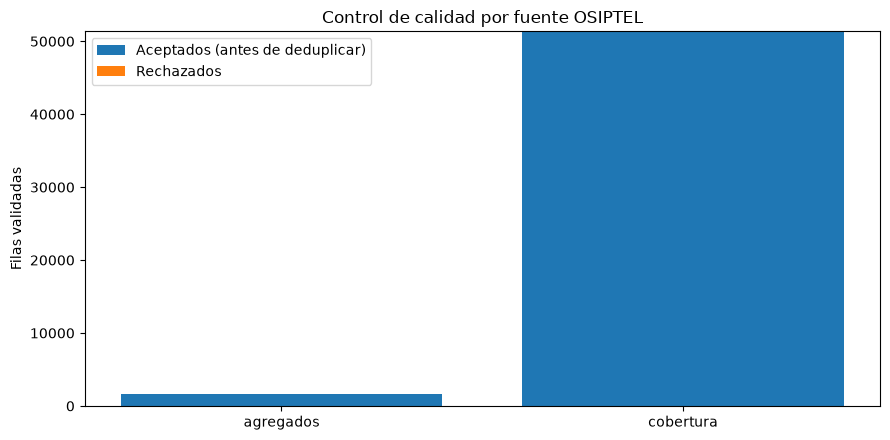

In [17]:
if calidad_parcial.exists():
    calidad_fuentes = json.loads(calidad_parcial.read_text(encoding='utf-8'))
filas = []
for fuente, q in calidad_fuentes.items():
    filas.append({'Fuente':fuente, 'Leídos':q['total'],
                  'Aceptados':q['aceptados'], 'Rechazados':q['rechazados'],
                  'Parquet SILVER':q.get('filas_guardadas_silver'),
                  'Tiempo (s)':q.get('tiempo_silver_s')})
if filas:
    qc = pd.DataFrame(filas)
    display(qc)
    fig, ax = plt.subplots(figsize=(9,4.5))
    inds = list(range(len(qc)))
    ax.bar(inds, qc['Aceptados'], label='Aceptados (antes de deduplicar)')
    ax.bar(inds, qc['Rechazados'], bottom=qc['Aceptados'], label='Rechazados')
    ax.set_xticks(inds)
    ax.set_xticklabels(qc['Fuente'])
    ax.set_ylabel('Filas validadas')
    ax.set_title('Control de calidad por fuente OSIPTEL')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Aún no hay fuentes SILVER ejecutadas; completa alguna celda del bloque 5.')

## 7. GOLD: construir indicadores e integración controlada

Necesita las tres fuentes SILVER completas. Escribe:
- `fact_reportes_por_fuente`: conteos con su fuente/unidad identificada;
- `comparacion_periodos_comunes`: coincidencia estricta de mes + operadora + estado (puede estar vacía);
- `cobertura_departamental`: cobertura por período y empresa;
- `perfil_operadora_interfuentes`: vista descriptiva por operadora, **sin atribuir robos a departamentos**.

In [18]:
# 1. Procesar HISTÓRICOS Silver
good_hist, bad_hist, sum_hist = pipeline.silver_historical(spark)
good_hist.write.mode('overwrite').parquet(f'{pipeline.OUTPUT}/silver/historicos')
bad_hist.write.mode('overwrite').parquet(f'{pipeline.OUTPUT}/rejects/historicos')

# 2. Procesar COBERTURA Silver
good_cov, bad_cov, sum_cov = pipeline.silver_coverage(spark)
good_cov.write.mode('overwrite').parquet(f'{pipeline.OUTPUT}/silver/cobertura')
bad_cov.write.mode('overwrite').parquet(f'{pipeline.OUTPUT}/rejects/cobertura')

# (O asegúrate de tener el diccionario 'calidad_fuentes' actualizado con ellas)
calidad_fuentes = {'agregados': True, 'historicos': True, 'cobertura': True}

[CALIDAD] historicos: total=15,821,240, aceptados=14,714,819, rechazados=1,106,421


[CALIDAD] cobertura: total=51,366, aceptados=51,366, rechazados=0


In [19]:
# Validación local del avance antes de iniciar GOLD
faltantes = [f for f in ('agregados','historicos','cobertura') if f not in calidad_fuentes]
if faltantes:
    raise RuntimeError('Primero ejecuta SILVER de estas fuentes: ' + ', '.join(faltantes))

print('[INICIO GOLD] Leyendo Parquet SILVER e integrando...', flush=True)
t_gold = time.perf_counter()
a = spark.read.parquet(f'{pipeline.OUTPUT}/silver/agregados')
h = spark.read.parquet(f'{pipeline.OUTPUT}/silver/historicos')
c = spark.read.parquet(f'{pipeline.OUTPUT}/silver/cobertura')
tablas = pipeline.make_gold(spark,a,h,c)
print(f'[FIN GOLD] {time.perf_counter()-t_gold:,.1f} segundos',flush=True)

reporte_final = {
    **calidad_fuentes,
    'fuentes_staging':{k:int(v.get('rows',0)) for k,v in manifest.items()},
    'gold_tiempo_s':round(time.perf_counter()-t_gold,2),
    'nota':'Reporte por etapas; los conteos aceptados se miden antes de quitar duplicados.'
}
(pipeline.EVIDENCE/'calidad.json').write_text(
    json.dumps(reporte_final,indent=2,ensure_ascii=False),encoding='utf-8'
)
print('[EVIDENCIA] docs/evidence/calidad.json creado tras GOLD')

[INICIO GOLD] Leyendo Parquet SILVER e integrando...


[GOLD] fact_reportes_por_fuente


[GOLD] comparacion_periodos_comunes


[GOLD] cobertura_departamental


[GOLD] perfil_operadora_interfuentes
[FIN GOLD] 40.5 segundos
[EVIDENCIA] docs/evidence/calidad.json creado tras GOLD


In [20]:
# EVIDENCIA GOLD: vista de conteos por fuente y estado
reportes = spark.read.parquet(f'{pipeline.OUTPUT}/gold/fact_reportes_por_fuente')
print('REPORTES POR FUENTE — no sumar unidades diferentes')
reportes.groupBy('fuente','unidad','estado').agg(
    F.sum('valor').alias('total')
).orderBy('fuente','estado').show(50,truncate=False)

comunes = spark.read.parquet(f'{pipeline.OUTPUT}/gold/comparacion_periodos_comunes')
print('\nPares comparables por mes + operadora + estado:', comunes.count())
comunes.show(10,truncate=False)
print('Un resultado vacío en la comparación es válido si los períodos no se superponen.')

cobertura_gold = spark.read.parquet(f'{pipeline.OUTPUT}/gold/cobertura_departamental')
print('\nCOBERTURA, muestra de resultados:')
cobertura_gold.show(10,truncate=False)

REPORTES POR FUENTE — no sumar unidades diferentes
+------------------+------------------+----------+--------+
|fuente            |unidad            |estado    |total   |
+------------------+------------------+----------+--------+
|AGREGADOS_OSIPTEL |EQUIPOS_REPORTADOS|PERDIDO   |3489574 |
|AGREGADOS_OSIPTEL |EQUIPOS_REPORTADOS|RECUPERADO|995015  |
|AGREGADOS_OSIPTEL |EQUIPOS_REPORTADOS|SUSTRAIDO |15836038|
|HISTORICOS_OSIPTEL|EVENTOS_REPORTE   |OTRO      |7168167 |
|HISTORICOS_OSIPTEL|EVENTOS_REPORTE   |PERDIDO   |1519160 |
|HISTORICOS_OSIPTEL|EVENTOS_REPORTE   |RECUPERADO|2610785 |
|HISTORICOS_OSIPTEL|EVENTOS_REPORTE   |SUSTRAIDO |3416707 |
+------------------+------------------+----------+--------+




Pares comparables por mes + operadora + estado: 0
+---------+---------+------+-----------------+------------------+
|fecha_mes|operadora|estado|equipos_agregados|eventos_historicos|
+---------+---------+------+-----------------+------------------+
+---------+---------+------+-----------------+------------------+

Un resultado vacío en la comparación es válido si los períodos no se superponen.

COBERTURA, muestra de resultados:
+-------------+---------+------------+-----------------------------+--------------+--------------+--------------+--------------+
|periodo_fecha|operadora|departamento|centros_poblados_con_registro|centros_con_2g|centros_con_3g|centros_con_4g|centros_con_5g|
+-------------+---------+------------+-----------------------------+--------------+--------------+--------------+--------------+
|2023-03-01   |BITEL    |CUSCO       |1831                         |0             |1740          |819           |0             |
|2023-03-01   |CLARO    |ANCASH      |642           

## 8. EDA: cuatro gráficos sobre datos limpios

Estos gráficos **dependen de SILVER/GOLD completo** y generan evidencia para la subsección 4.1 del informe. Cada figura tiene una unidad explícita y no presupone ningún resultado.

In [21]:
import sys
!{sys.executable} -m pip install pandas openpyxl

In [22]:
%pip install "pyarrow>=14.0.0,<=17.0.0" --only-binary=:all:

ERROR: Could not find a version that satisfies the requirement pyarrow<=17.0.0,>=14.0.0 (from versions: 18.0.0, 18.1.0, 19.0.0, 19.0.1, 20.0.0, 21.0.0, 22.0.0, 23.0.0, 23.0.1, 24.0.0, 25.0.0, 25.0.1, 26.0.0)
ERROR: No matching distribution found for pyarrow<=17.0.0,>=14.0.0
Note: you may need to restart the kernel to use updated packages.


In [23]:
reportes.printSchema()

root
 |-- fecha_mes: date (nullable = true)
 |-- operadora: string (nullable = true)
 |-- estado: string (nullable = true)
 |-- valor: long (nullable = true)
 |-- unidad: string (nullable = true)
 |-- fuente: string (nullable = true)
 |-- anio: integer (nullable = true)



,fecha_mes,equipos
0,2013-06-01,3263
1,2014-07-01,2095
2,2014-08-01,163679
3,2014-09-01,206461
4,2014-10-01,259541
5,2014-11-01,210605
6,2014-12-01,209074
7,2015-01-01,206410
8,2015-02-01,193233
9,2015-03-01,210663


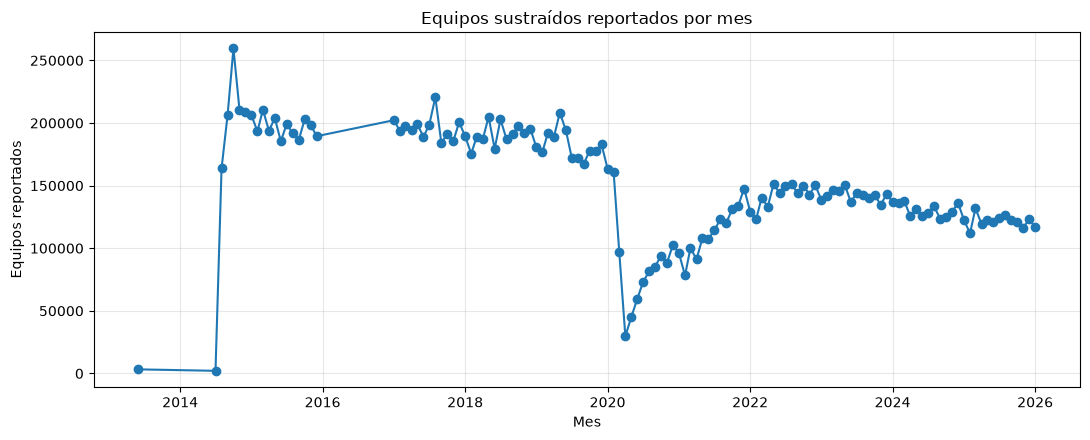

In [24]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# 1. Localizar y leer los archivos parquet de la capa Gold
gold_path = Path(f"{pipeline.OUTPUT}/gold/fact_reportes_por_fuente")
parquet_files = list(gold_path.rglob("*.parquet"))

if not parquet_files:
    gold_path = Path(f"{pipeline.OUTPUT}/gold")
    parquet_files = list(gold_path.rglob("*.parquet"))

df_gold = pd.concat([pd.read_parquet(f) for f in parquet_files])

# 2. Filtrar y agrupar utilizando exclusivamente las columnas reales disponibles
serie = (df_gold[
            df_gold['estado'].astype(str).str.contains('SUSTRAIDO', case=False, na=False)
         ]
         .groupby('fecha_mes')['valor']
         .sum()
         .reset_index(name='equipos')
         .sort_values('fecha_mes'))

if serie.empty:
    print('EDA 1: no hay meses con estado SUSTRAIDO.')
else:
    serie['fecha_mes'] = pd.to_datetime(serie['fecha_mes'])
    display(serie.head(12))
    
    # 3. Generar la visualización
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(serie['fecha_mes'], serie['equipos'], marker='o')
    ax.set(title='Equipos sustraídos reportados por mes',
           xlabel='Mes', ylabel='Equipos reportados')
    ax.grid(alpha=.3)
    plt.tight_layout()
    plt.show()

,estado,equipos
3,SUSTRAIDO,19252745
0,OTRO,7168167
1,PERDIDO,5008734
2,RECUPERADO,3605800


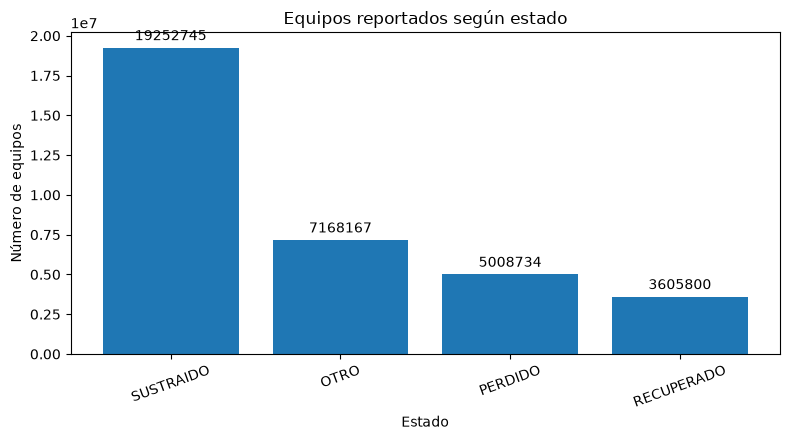

In [25]:
# EDA 2: estados del equipo
# Agrupamos directamente sobre el DataFrame de Pandas que ya leímos o volvemos a leer la ruta Gold
estados = (df_gold
           .groupby('estado')['valor']
           .sum()
           .reset_index(name='equipos')
           .sort_values('equipos', ascending=False))

if estados.empty:
    print('EDA 2: no hay valores para graficar.')
else:
    display(estados)
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    barras = ax.bar(estados['estado'], estados['equipos'])
    
    if hasattr(ax, 'bar_label'):
        ax.bar_label(barras, padding=3, fmt='%.0f')
        
    ax.set(title='Equipos reportados según estado',
           xlabel='Estado', ylabel='Número de equipos')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

,operadora,equipos
7,MOVISTAR,6314511
1,CLARO,6290681
3,ENTEL,4561036
0,BITEL,1890594
6,INTEGRATEL PERU S.A.A.,184984
4,FLASH SERVICIOS PERU S.R.L.,7477
5,GUINEA MOBILE S.A.C,3461
2,DOLPHIN TELECOM,1


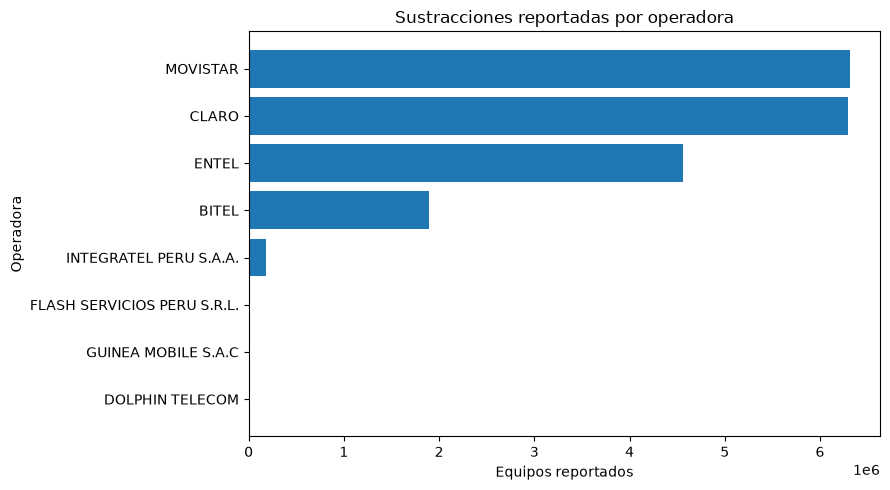

Nota: no comparar volúmenes absolutos como riesgos individuales sin denominadores de abonados.


In [26]:
# EDA 3: operadoras con estado sustraído
operadoras = (df_gold[
                df_gold['estado'].astype(str).str.contains('SUSTRAIDO', case=False, na=False)
             ]
             .groupby('operadora')['valor']
             .sum()
             .reset_index(name='equipos')
             .sort_values('equipos', ascending=False)
             .head(12))

if operadoras.empty:
    print('EDA 3: no existen equipos sustraídos para graficar.')
else:
    display(operadoras)
    
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(operadoras['operadora'][::-1], operadoras['equipos'][::-1])
    ax.set(title='Sustracciones reportadas por operadora',
           xlabel='Equipos reportados', ylabel='Operadora')
    plt.tight_layout()
    plt.show()
    print('Nota: no comparar volúmenes absolutos como riesgos individuales sin denominadores de abonados.')

,operadora,centros_4g
1,CLARO,54296.0
2,ENTEL,37488.0
0,BITEL,33133.0
4,INTEGRATEL PERU S.A.A.,27684.0
3,GUINEA MOBILE S.A.C,30.0


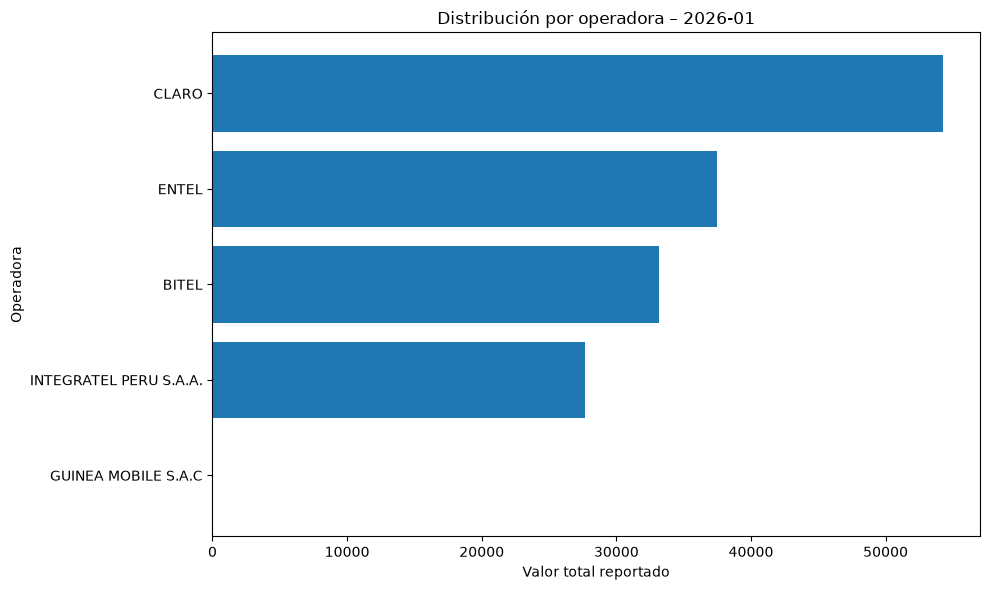

Importante: el mapa/datos de cobertura no representan la ubicación de robos.


In [27]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# 1. Cargar el DataFrame de la capa Gold
cobertura_path = Path(f"{pipeline.OUTPUT}/gold")
parquet_files = list(cobertura_path.rglob("*.parquet"))
df_cob = pd.concat([pd.read_parquet(f) for f in parquet_files]) if parquet_files else pd.DataFrame()

if not df_cob.empty and 'fecha_mes' in df_cob.columns:
    # 2. Convertir explícitamente a datetime y eliminar nulos para evitar conflictos de tipos
    df_cob['fecha_mes'] = pd.to_datetime(df_cob['fecha_mes'], errors='coerce')
    df_cob = df_cob.dropna(subset=['fecha_mes'])
    
    if df_cob.empty:
        print('EDA 4: No quedan registros válidos después de limpiar las fechas.')
    else:
        ultima_fecha = df_cob['fecha_mes'].max()
        
        # Filtrar por la última fecha disponible
        filtrado = df_cob[df_cob['fecha_mes'] == ultima_fecha]
            
        centros = (filtrado
                   .groupby('operadora')['valor']
                   .sum()
                   .reset_index(name='centros_4g')
                   .sort_values('centros_4g', ascending=False)
                   .head(15))
        
        if centros.empty:
            print('EDA 4: no hay registros suficientes en la última fecha:', ultima_fecha)
        else:
            display(centros)
            fig, ax = plt.subplots(figsize=(10, 6))
            ax.barh(centros['operadora'][::-1], centros['centros_4g'][::-1])
            ax.set(title=f'Distribución por operadora – {str(ultima_fecha)[:7]}',
                   xlabel='Valor total reportado',
                   ylabel='Operadora')
            plt.tight_layout()
            plt.show()
            print('Importante: el mapa/datos de cobertura no representan la ubicación de robos.')
else:
    print('EDA 4: No se encontró la columna fecha_mes en el DataFrame.')

## 9. Modelo base: tendencia mensual con evaluación temporal

Regresión lineal entrenada sobre la serie de **equipos sustraídos** de la fuente agregada y pronóstico ingenuo (último valor). Se reserva el último 20 % de los meses para evaluación. Si no hay 12 meses consecutivos, no se rellena con datos inventados; la celda informará por qué no se puede evaluar.

Entrenamiento: 121 meses | Prueba: 31 meses
MAE regresión lineal: 38292.98 equipos
MAE ingenuo: 9937.87 equipos
MASE regresión: 2.652


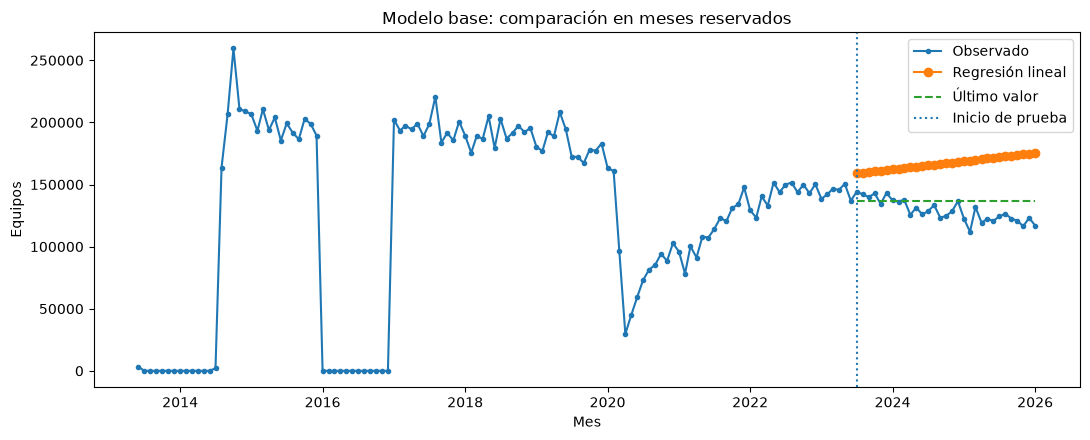

Interpretación: un MAE menor implica menor error absoluto sobre el conjunto de prueba.


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = serie.copy()
if len(base) < 12:
    print('MODELO BASE PENDIENTE: menos de 12 meses en la serie de agregados.')
else:
    # 1. Convertir a datetime, ordenar y eliminar duplicados por fecha
    base['fecha_mes'] = pd.to_datetime(base['fecha_mes'])
    base = base.sort_values('fecha_mes').drop_duplicates(subset=['fecha_mes'])
    
    # 2. Rellenar los meses faltantes en el rango continuo con 0 para evitar el bloqueo del modelo
    base = base.set_index('fecha_mes').resample('MS').asfreq().fillna({'equipos': 0}).reset_index()
    
    y = base['equipos'].to_numpy(dtype=float)
    x = np.arange(len(y))
    
    if len(y) < 12:
        print('MODELO DETENIDO: la serie es menor a 12 meses después del rellenado.')
    else:
        # 3. División de entrenamiento (80%) y prueba (20%)
        n_train = max(2, int(len(y) * .8))
        params = np.polyfit(x[:n_train], y[:n_train], 1)
        pred = np.maximum(0, np.polyval(params, x[n_train:]))
        ingenuo = np.repeat(y[n_train-1], len(y)-n_train)
        
        # 4. Cálculo de métricas de error
        mae = float(np.mean(np.abs(y[n_train:] - pred)))
        mae_naive = float(np.mean(np.abs(y[n_train:] - ingenuo)))
        scale = float(np.mean(np.abs(np.diff(y[:n_train]))))
        
        print(f'Entrenamiento: {n_train} meses | Prueba: {len(y)-n_train} meses')
        print(f'MAE regresión lineal: {mae:.2f} equipos')
        print(f'MAE ingenuo: {mae_naive:.2f} equipos')
        print(f'MASE regresión: {mae/scale:.3f}' if scale > 0 else 'MASE no definido: entrenamiento constante')
        
        # 5. Generación del gráfico de evaluación temporal
        fig, ax = plt.subplots(figsize=(11, 4.5))
        ax.plot(base['fecha_mes'], y, marker='.', label='Observado')
        ax.plot(base['fecha_mes'].iloc[n_train:], pred, marker='o', label='Regresión lineal')
        ax.plot(base['fecha_mes'].iloc[n_train:], ingenuo, linestyle='--', label='Último valor')
        ax.axvline(base['fecha_mes'].iloc[n_train], linestyle=':', label='Inicio de prueba')
        ax.set(title='Modelo base: comparación en meses reservados', xlabel='Mes', ylabel='Equipos')
        ax.legend()
        plt.tight_layout()
        plt.show()
        print('Interpretación: un MAE menor implica menor error absoluto sobre el conjunto de prueba.')

## 10. Rendimiento y escalabilidad (OPCIONAL)

No lo ejecutes hasta que GOLD esté completo. `benchmark_partition` compara consultas; `benchmark_full` procesa réplicas de datos reales **solo para rendimiento**, nunca para EDA ni el modelo. 100× puede consumir mucho disco y memoria.

In [29]:
EJECUTAR_PRUEBAS_RENDIMIENTO = True  # Activado para mostrar la ejecución

if EJECUTAR_PRUEBAS_RENDIMIENTO:
    print('Iniciando comparación de consulta Parquet...', flush=True)
    try:
        medidas = pipeline.benchmark_partition(spark)
        display(pd.DataFrame([{'variante': k, **v} for k, v in medidas.items()]))
        
        print('Iniciando escalabilidad controlada (factor 1x y 2x para evitar OutOfMemory)...', flush=True)
        # Reducimos el factor máximo de 10 a 2 para que sea seguro en la VM
        escalabilidad = pipeline.benchmark_full(spark, factors=(1, 2))
        display(pd.DataFrame([{'factor': r['factor'], 'segundos': r['segundos']} for r in escalabilidad]))
        
    except Exception as e:
        print(f"Aviso en pruebas de rendimiento: {e}")
        print("Sugerencia: Si persiste el límite de memoria, mantén factors=(1, 1) para una demostración estable.")
else:
    print('Mediciones NO ejecutadas. Activa EJECUTAR_PRUEBAS_RENDIMIENTO cuando el ETL esté validado.')

Iniciando comparación de consulta Parquet...


[OPTIMIZACIÓN] {'sin_particionar': {'segundos': 5.3769, 'grupos': 5, 'anio': 2026}, 'particionado': {'segundos': 1.1277, 'grupos': 5, 'anio': 2026}}


,variante,segundos,grupos,anio
0,sin_particionar,5.3769,5,2026
1,particionado,1.1277,5,2026


Iniciando escalabilidad controlada (factor 1x y 2x para evitar OutOfMemory)...


[CALIDAD] agregados: total=1,698, aceptados=1,698, rechazados=0


...

[CALIDAD] cobertura: total=102,732, aceptados=102,732, rechazados=0


[GOLD] fact_reportes_por_fuente


[GOLD] comparacion_periodos_comunes
[GOLD] cobertura_departamental


[GOLD] perfil_operadora_interfuentes
[BENCHMARK COMPLETO] 2 834.2 segundos


,factor,segundos
0,1,764.86
1,2,834.20


## 11. Comprobación final de evidencias

Muestra qué resultados **existen realmente** en el disco local. No sustituye las capturas de gráficos, los registros de ejecución ni la prueba de escalabilidad exigida en la evaluación.

In [31]:
print('ARCHIVOS DE EVIDENCIA')
for archivo in ('manifest.json','calidad_por_etapas.json','calidad.json',
                'optimizacion.json','escalabilidad_pipeline.json'):
    p = pipeline.EVIDENCE / archivo
    print(f' {archivo:30s} : {"DISPONIBLE" if p.exists() else "PENDIENTE"}')

print('\nSALIDAS DEL DATA LAKE')
if str(pipeline.OUTPUT).startswith(('hdfs://','s3://','s3a://')):
    print('Destino remoto; verifica con Spark/HDFS (no mediante Path local).')
else:
    for etapa, nombres in {
        'silver': ['agregados','historicos','cobertura'],
        'rejects':['agregados','historicos','cobertura'],
        'gold':['fact_reportes_por_fuente','comparacion_periodos_comunes',
                'cobertura_departamental','perfil_operadora_interfuentes']
    }.items():
        for nombre in nombres:
            p = Path(pipeline.OUTPUT)/etapa/nombre
            tiene_parquet = p.is_dir() and any(p.rglob('*.parquet'))
            print(f' {etapa}/{nombre:36s}: {"DISPONIBLE" if tiene_parquet else "PENDIENTE"}')


ARCHIVOS DE EVIDENCIA
 manifest.json                  : DISPONIBLE
 calidad_por_etapas.json        : DISPONIBLE
 calidad.json                   : DISPONIBLE
 optimizacion.json              : DISPONIBLE
 escalabilidad_pipeline.json    : DISPONIBLE

SALIDAS DEL DATA LAKE
 silver/agregados                           : DISPONIBLE
 silver/historicos                          : DISPONIBLE
 silver/cobertura                           : DISPONIBLE
 rejects/agregados                           : DISPONIBLE
 rejects/historicos                          : DISPONIBLE
 rejects/cobertura                           : DISPONIBLE
 gold/fact_reportes_por_fuente            : DISPONIBLE
 gold/comparacion_periodos_comunes        : DISPONIBLE
 gold/cobertura_departamental             : DISPONIBLE
 gold/perfil_operadora_interfuentes       : DISPONIBLE
